In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
import tensorflow as tf

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [3]:
MAX_INTENSITY = 255.0
x_train_full = x_train_full.astype("float32") / MAX_INTENSITY
x_test = x_test.astype("float32") / MAX_INTENSITY

N_TRAIN = 50_000
x_val, y_val = x_train_full[N_TRAIN:], y_train_full[N_TRAIN:]
x_train, y_train = x_train_full[:N_TRAIN], y_train_full[:N_TRAIN]

In [4]:
CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", 
               "Dress", "Coat", "Sandal", "Shirt", 
               "Sneaker", "Bag", "Ankle boot"]


In [5]:
print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}, class: {len(CLASS_NAMES)}")

train: (50000, 28, 28), val: (10000, 28, 28), test: (10000, 28, 28), class: 10


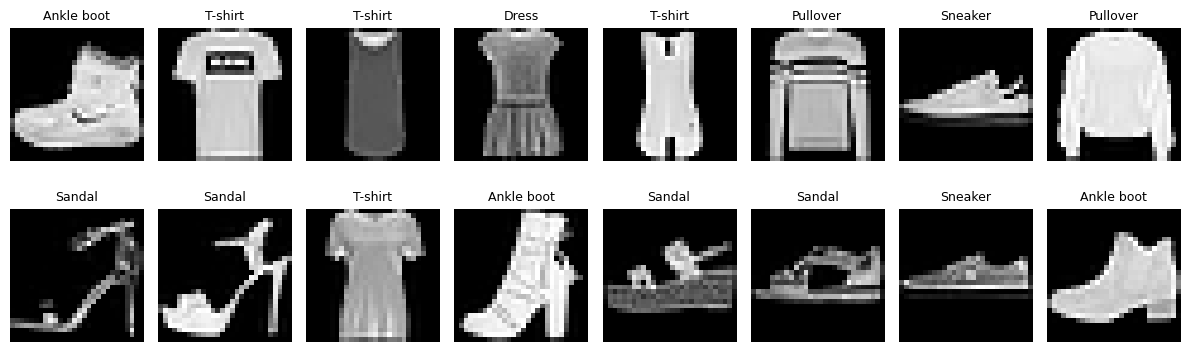

In [6]:
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for ax, img, label in zip(axes.flat, x_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Reduce LR on plateau

In [8]:
model = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)


history = model.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=64, verbose=0)

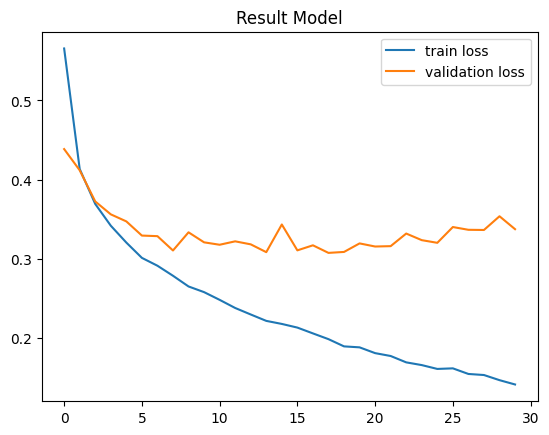

In [10]:
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.title("Result Model")
plt.legend()
plt.show()

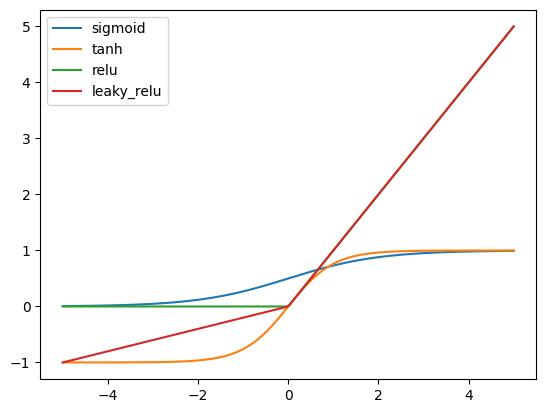

In [30]:
x = np.linspace(-5, 5, 200)

plt.plot(x, keras.activations.sigmoid(x), label="sigmoid")
plt.plot(x, keras.activations.tanh(x), label="tanh")
plt.plot(x, keras.activations.relu(x), label="relu")
plt.plot(x, keras.activations.leaky_relu(x), label="leaky_relu")
plt.legend()
plt.show()

In [27]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.8, patience=3)

model_relu = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model_relu.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)


history_relu = model_relu.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=64, verbose=0, callbacks=[reduce_lr])

In [28]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.8, patience=3)

model_sigmoid = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(64, activation="sigmoid"),
    layers.Dense(64, activation="sigmoid"),
    layers.Dense(64, activation="sigmoid"),
    layers.Dense(64, activation="sigmoid"),
    layers.Dense(64, activation="sigmoid"),
    layers.Dense(32, activation="sigmoid"),
    layers.Dense(32, activation="sigmoid"),
    layers.Dense(10, activation="softmax")
])

model_sigmoid.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)


history_sigmoid = model_sigmoid.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=64, verbose=0, callbacks=[reduce_lr])

In [29]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.8, patience=3)

model_tanh = keras.Sequential([
    keras.layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(64, activation="tanh"),
    layers.Dense(64, activation="tanh"),
    layers.Dense(64, activation="tanh"),
    layers.Dense(64, activation="tanh"),
    layers.Dense(64, activation="tanh"),
    layers.Dense(32, activation="tanh"),
    layers.Dense(32, activation="tanh"),
    layers.Dense(10, activation="softmax")
])

model_tanh.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)


history_tanh = model_tanh.fit(x_train, y_train, validation_split=0.2, epochs=30, batch_size=64, verbose=0, callbacks=[reduce_lr])

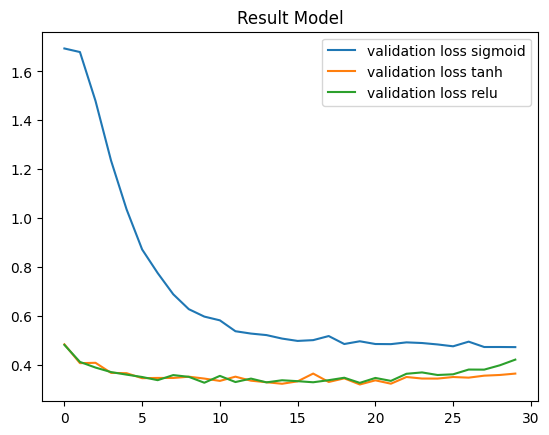

In [31]:
plt.plot(history_sigmoid.history["val_loss"], label="validation loss sigmoid")
plt.plot(history_tanh.history["val_loss"], label="validation loss tanh")
plt.plot(history_relu.history["val_loss"], label="validation loss relu")
plt.title("Result Model")
plt.legend()
plt.show()

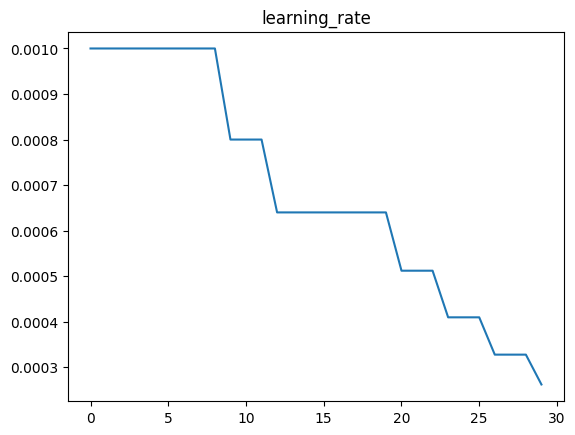

In [32]:
plt.plot(history.history["learning_rate"])
plt.title("learning_rate")
plt.show()

In [72]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
result_early_stop = model_early_stop.fit(x_train, y_train, validation_split=0.2, epochs=80, batch_size=32, callbacks=[early_stop])

Epoch 1/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8134 - loss: 0.5352 - val_accuracy: 0.8510 - val_loss: 0.4223
Epoch 2/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.8579 - loss: 0.3991 - val_accuracy: 0.8650 - val_loss: 0.3834
Epoch 3/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.8705 - loss: 0.3559 - val_accuracy: 0.8702 - val_loss: 0.3634
Epoch 4/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8785 - loss: 0.3304 - val_accuracy: 0.8765 - val_loss: 0.3508
Epoch 5/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8843 - loss: 0.3119 - val_accuracy: 0.8803 - val_loss: 0.3346
Epoch 6/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8921 - loss: 0.2935 - val_accuracy: 0.8817 - val_loss: 0.3191
Epoch 7/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8984 - loss: 0.2767 - val_accuracy: 0.8858 - val_loss: 0.3295
Epoch 8/80
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9003 - loss: 0.2688 -

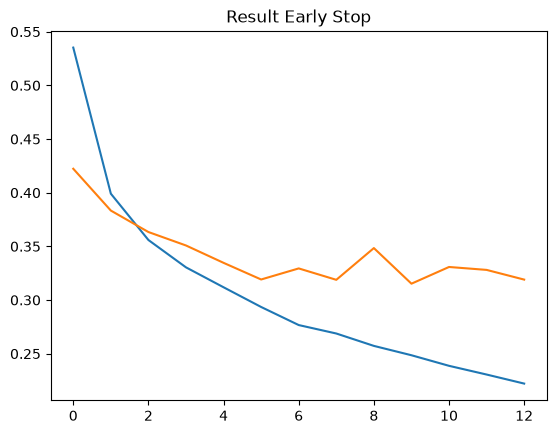

In [73]:
plt.plot(result_early_stop.history["loss"], label="train loss model_1")
plt.plot(result_early_stop.history["val_loss"], label="validation loss model_1")
plt.title("Result Early Stop")
plt.show()